In [3]:
!pip install -q opencv-python-headless
!pip install -q numpy pandas matplotlib
!pip install -q librosa soundfile
!pip install -q transformers datasets
!pip install -q jiwer
!pip install -q mediapipe

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Check Runtime settings.")


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_PATH = "/content/drive/MyDrive/data (1)"

VIDEO_PATH = os.path.join(PROJECT_PATH, "s1")
ALIGN_PATH = os.path.join(PROJECT_PATH, "alignments", "s1")

OUTPUT_PATH = os.path.join(PROJECT_PATH, "outputs")

os.makedirs(OUTPUT_PATH, exist_ok=True)

print("Video folder exists:", os.path.exists(VIDEO_PATH))
print("Alignment folder exists:", os.path.exists(ALIGN_PATH))
print("Output folder:", OUTPUT_PATH)


Video folder exists: True
Alignment folder exists: True
Output folder: /content/drive/MyDrive/data (1)/outputs


In [12]:
from google.colab import drive
import os
import glob


drive.mount('/content/drive')


BASE_PATH = "/content/drive/MyDrive/data (1)"
VIDEO_PATH = os.path.join(BASE_PATH, "s1")
ALIGN_PATH = os.path.join(BASE_PATH, "alignments", "s1")
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")

# Create output folder
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Verify folders
print("Base folder exists:", os.path.exists(BASE_PATH))
print("Video folder exists:", os.path.exists(VIDEO_PATH))
print("Alignment folder exists:", os.path.exists(ALIGN_PATH))

# Count files
videos = glob.glob(os.path.join(VIDEO_PATH, "*.mpg"))
alignments = glob.glob(os.path.join(ALIGN_PATH, "*.align"))

print("\nTotal MPG videos:", len(videos))
print("Total alignment files:", len(alignments))

# Check matching filenames
video_names = {os.path.splitext(os.path.basename(f))[0] for f in videos}
align_names = {os.path.splitext(os.path.basename(f))[0] for f in alignments}

print("Matching pairs:", len(video_names & align_names))
print("Videos without alignment:", len(video_names - align_names))
print("Alignments without video:", len(align_names - video_names))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base folder exists: True
Video folder exists: True
Alignment folder exists: True

Total MPG videos: 1016
Total alignment files: 1000
Matching pairs: 1000
Videos without alignment: 16
Alignments without video: 0


In [13]:


if len(alignments) > 0:
    sample_align = alignments[0]

    print("File:", os.path.basename(sample_align))
    print("\nAlignment contents:\n")

    with open(sample_align, "r") as f:
        print(f.read())
else:
    print("No alignment files found.")

File: bbaf2n.align

Alignment contents:

0 23750 sil
23750 29500 bin
29500 34000 blue
34000 35500 at
35500 41000 f
41000 47250 two
47250 53000 now
53000 74500 sil



In [14]:
import cv2

if len(videos) > 0:
    sample_video = videos[0]

    cap = cv2.VideoCapture(sample_video)

    print("Video:", os.path.basename(sample_video))
    print("Video opened:", cap.isOpened())
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
    print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

    cap.release()
else:
    print("No videos found.")

Video: bbbf7s.mpg
Video opened: True
FPS: 25.0
Total frames: 75
Width: 360
Height: 288


In [15]:
!ffmpeg -version

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --enable-

In [16]:
import subprocess
import os

result = subprocess.run(
    ["ffmpeg", "-version"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("FFmpeg is installed!")
    print(result.stdout.splitlines()[0])
else:
    print("Installing FFmpeg...")
    !apt-get -qq install -y ffmpeg

FFmpeg is installed!
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


In [17]:
video_dict = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in videos
}

align_dict = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in alignments
}

matching_names = sorted(set(video_dict) & set(align_dict))

print("Matching pairs:", len(matching_names))

if matching_names:
    sample_name = matching_names[0]
    sample_video = video_dict[sample_name]
    sample_align = align_dict[sample_name]

    print("Selected video:", os.path.basename(sample_video))
    print("Selected alignment:", os.path.basename(sample_align))
else:
    print("No matching video-alignment pairs found.")

Matching pairs: 1000
Selected video: bbaf2n.mpg
Selected alignment: bbaf2n.align


In [18]:
import subprocess
import os

AUDIO_PATH = os.path.join(OUTPUT_PATH, "audio")
os.makedirs(AUDIO_PATH, exist_ok=True)

sample_wav = os.path.join(AUDIO_PATH, sample_name + ".wav")

subprocess.run([
    "ffmpeg",
    "-y",
    "-i", sample_video,
    "-vn",
    "-ac", "1",
    "-ar", "16000",
    sample_wav
], check=True)

print("Audio extracted successfully!")
print("Saved at:", sample_wav)

Audio extracted successfully!
Saved at: /content/drive/MyDrive/data (1)/outputs/audio/bbaf2n.wav


In [19]:
import soundfile as sf
import numpy as np

audio, sr = sf.read(sample_wav)

print("Sample rate:", sr, "Hz")
print("Duration:", round(len(audio) / sr, 3), "seconds")
print("Audio shape:", audio.shape)
print("Minimum amplitude:", np.min(audio))
print("Maximum amplitude:", np.max(audio))
print("Audio contains valid values:", np.isfinite(audio).all())

Sample rate: 16000 Hz
Duration: 2.978 seconds
Audio shape: (47648,)
Minimum amplitude: -0.765045166015625
Maximum amplitude: 0.999969482421875
Audio contains valid values: True


In [20]:
from IPython.display import Audio, display

display(Audio(audio, rate=sr))

In [22]:
import pandas as pd

alignment_data = []

with open(sample_align, "r") as f:
    for line in f:
        start, end, word = line.strip().split()

        alignment_data.append({
            "start_seconds": int(start) / 100000,
            "end_seconds": int(end) / 100000,
            "word": word
        })

alignment_df = pd.DataFrame(alignment_data)

print(alignment_df.to_string(index=False))


 start_seconds  end_seconds word
        0.0000       0.2375  sil
        0.2375       0.2950  bin
        0.2950       0.3400 blue
        0.3400       0.3550   at
        0.3550       0.4100    f
        0.4100       0.4725  two
        0.4725       0.5300  now
        0.5300       0.7450  sil


In [23]:
print("Audio duration:", round(len(audio) / sr, 3), "seconds")
print("Video duration:", round(75 / 25, 3), "seconds")
print("Alignment duration:", alignment_df["end_seconds"].max(), "seconds")

print("\nAudio remaining after alignment:",
      round((len(audio) / sr) - alignment_df["end_seconds"].max(), 3),
      "seconds")

Audio duration: 2.978 seconds
Video duration: 3.0 seconds
Alignment duration: 0.745 seconds

Audio remaining after alignment: 2.233 seconds


In [24]:
print("Raw alignment file:")
with open(sample_align, "r") as f:
    for line in f:
        print(repr(line))

Raw alignment file:
'0 23750 sil\n'
'23750 29500 bin\n'
'29500 34000 blue\n'
'34000 35500 at\n'
'35500 41000 f\n'
'41000 47250 two\n'
'47250 53000 now\n'
'53000 74500 sil\n'


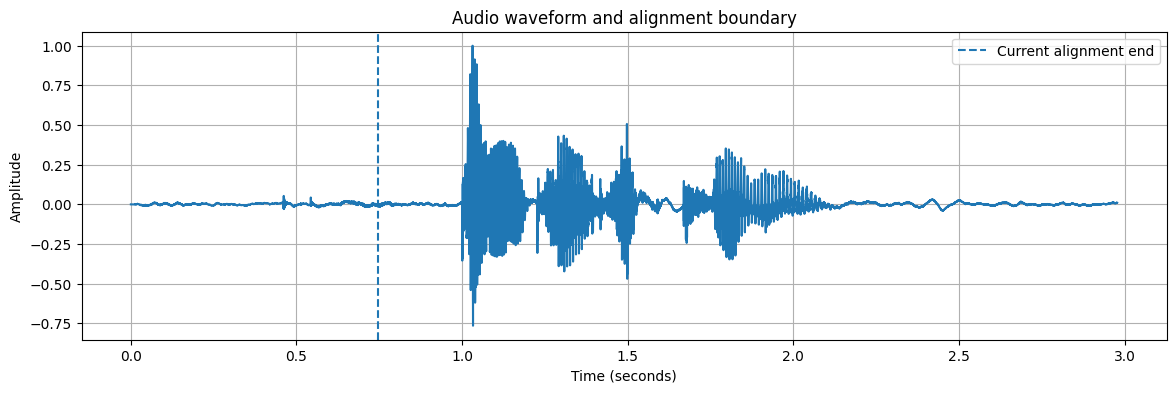

In [25]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(14, 4))

time_axis = np.arange(len(audio)) / sr
plt.plot(time_axis, audio)

plt.axvline(0.745, linestyle="--", label="Current alignment end")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Audio waveform and alignment boundary")
plt.legend()
plt.grid()
plt.show()


In [26]:
alignment_data = []

with open(sample_align, "r") as f:
    for line in f:
        start, end, word = line.strip().split()

        alignment_data.append({
            "start_seconds": int(start) / 25000,
            "end_seconds": int(end) / 25000,
            "word": word
        })

alignment_df = pd.DataFrame(alignment_data)

print(alignment_df.to_string(index=False))

print("\nAudio duration:", len(audio) / sr)
print("Alignment duration:", alignment_df["end_seconds"].max())


 start_seconds  end_seconds word
          0.00         0.95  sil
          0.95         1.18  bin
          1.18         1.36 blue
          1.36         1.42   at
          1.42         1.64    f
          1.64         1.89  two
          1.89         2.12  now
          2.12         2.98  sil

Audio duration: 2.978
Alignment duration: 2.98


In [27]:
import cv2
import pandas as pd
import os

validation_results = []

for name in matching_names[:5]:

    video_file = video_dict[name]
    align_file = align_dict[name]

    cap = cv2.VideoCapture(video_file)

    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)

    cap.release()

    video_duration = frames / fps

    with open(align_file, "r") as f:
        lines = f.readlines()

    last_end = int(lines[-1].split()[1])
    alignment_duration = last_end / 25000

    validation_results.append({
        "filename": name,
        "video_duration": round(video_duration, 3),
        "alignment_duration": round(alignment_duration, 3),
        "difference": round(abs(video_duration - alignment_duration), 3)
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

,filename,video_duration,alignment_duration,difference
0,bbaf2n,3.0,2.98,0.02
1,bbaf3s,3.0,2.98,0.02
2,bbaf4p,3.0,2.98,0.02
3,bbaf5a,3.0,2.98,0.02
4,bbal6n,3.0,2.98,0.02


In [28]:
import cv2
import os

FRAME_PATH = os.path.join(OUTPUT_PATH, "frames", sample_name)
os.makedirs(FRAME_PATH, exist_ok=True)

cap = cv2.VideoCapture(sample_video)

frame_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    frame_file = os.path.join(
        FRAME_PATH,
        f"frame_{frame_count:04d}.jpg"
    )

    cv2.imwrite(frame_file, frame)
    frame_count += 1

cap.release()

print("Frames extracted:", frame_count)
print("Saved in:", FRAME_PATH)

Frames extracted: 75
Saved in: /content/drive/MyDrive/data (1)/outputs/frames/bbaf2n


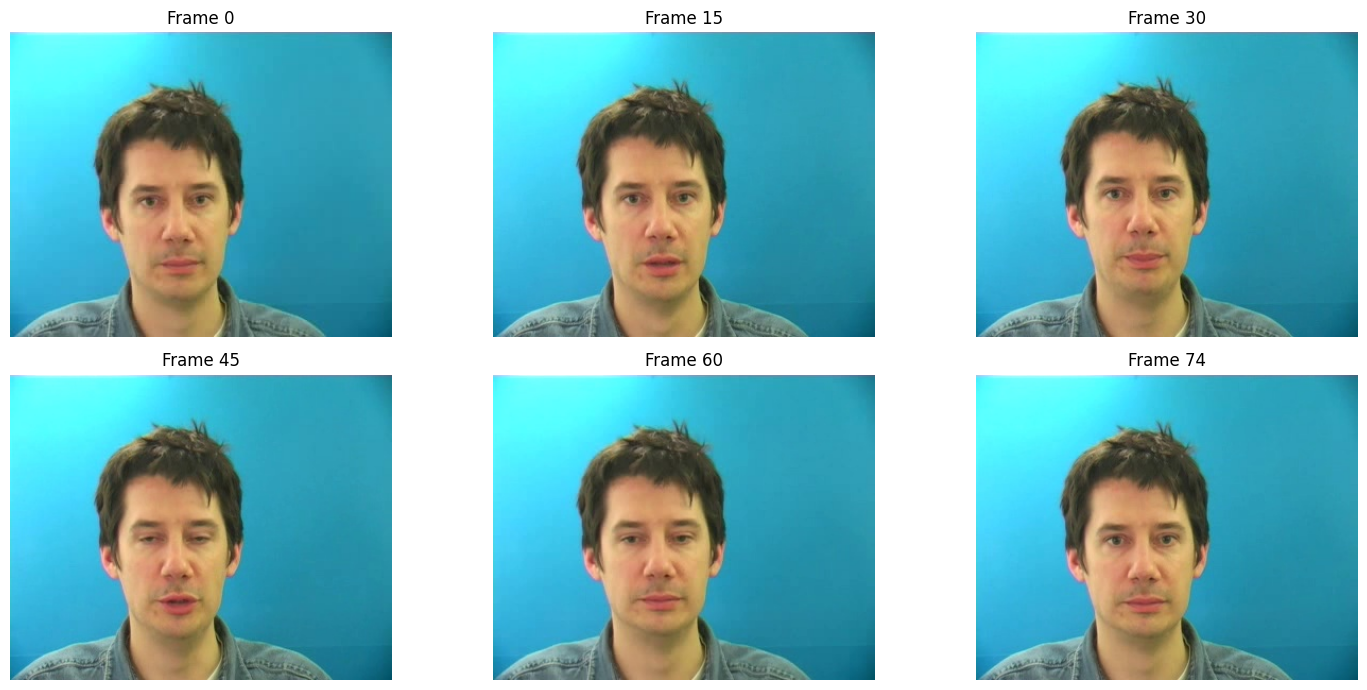

In [29]:

import matplotlib.pyplot as plt
import cv2
import os

sample_frames = [0, 15, 30, 45, 60, 74]

plt.figure(figsize=(15, 7))

for i, frame_number in enumerate(sample_frames):

    frame_file = os.path.join(
        FRAME_PATH,
        f"frame_{frame_number:04d}.jpg"
    )

    frame = cv2.imread(frame_file)
    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i + 1)
    plt.imshow(frame)
    plt.title(f"Frame {frame_number}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
!pip uninstall -y mediapipe
!pip install mediapipe==0.10.35

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 58.4 MB/s  0:00:00


In [2]:
import mediapipe as mp

print("MediaPipe version:", mp.__version__)
print("Solutions available:", hasattr(mp, "solutions"))

MediaPipe version: 0.10.35
Solutions available: False


In [4]:
import mediapipe as mp

print("MediaPipe location:", mp.__file__)
print("Tasks API available:", hasattr(mp, "tasks"))

if hasattr(mp, "tasks"):
    print("Vision API available:", hasattr(mp.tasks, "vision"))

MediaPipe location: /usr/local/lib/python3.13/dist-packages/mediapipe/__init__.py
Tasks API available: True
Vision API available: True


In [5]:
import os
import urllib.request

MODEL_PATH = "/content/face_landmarker.task"

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

if not os.path.exists(MODEL_PATH):
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

print("Model downloaded:", os.path.exists(MODEL_PATH))
print("Model size:", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2), "MB")

Model downloaded: True
Model size: 3.58 MB


In [6]:
import mediapipe as mp

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
VisionRunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=MODEL_PATH),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1
)

face_landmarker = FaceLandmarker.create_from_options(options)

print("Face Landmarker")

Face Landmarker


In [8]:
import os
import glob
import cv2

BASE_PATH = "/content/drive/MyDrive/data (1)"

VIDEO_PATH = os.path.join(BASE_PATH, "s1")
ALIGN_PATH = os.path.join(BASE_PATH, "align", "s1")
OUTPUT_PATH = os.path.join(BASE_PATH, "outputs")

FRAME_PATH = os.path.join(OUTPUT_PATH, "frames", "bbaf2n")
AUDIO_PATH = os.path.join(OUTPUT_PATH, "audio")
sample_wav = os.path.join(AUDIO_PATH, "bbaf2n.wav")

sample_video = os.path.join(VIDEO_PATH, "bbaf2n.mpg")
sample_align = os.path.join(ALIGN_PATH, "bbaf2n.align")

print("Video exists:", os.path.exists(sample_video))
print("Alignment exists:", os.path.exists(sample_align))
print("Frames folder exists:", os.path.exists(FRAME_PATH))
print("Audio exists:", os.path.exists(sample_wav))

Video exists: True
Alignment exists: False
Frames folder exists: True
Audio exists: True


In [9]:
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
frame_path = os.path.join(FRAME_PATH, "frame_0030.jpg")

image = cv2.imread(frame_path)

if image is None:
    raise FileNotFoundError(f"Frame not found: {frame_path}")


rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_image
)

result = face_landmarker.detect(mp_image)

print("Faces detected:", len(result.face_landmarks))

Faces detected: 1


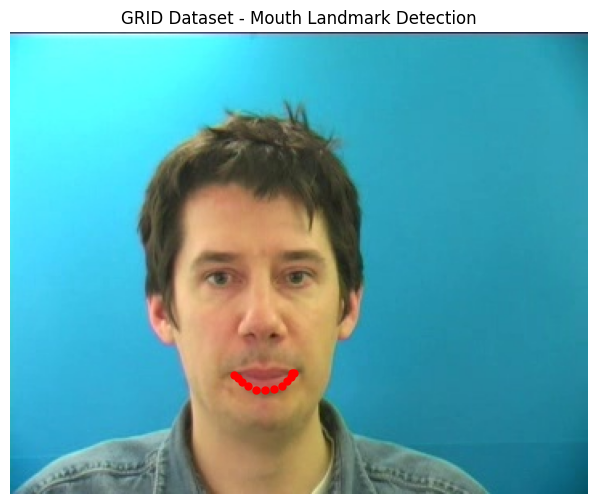

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(rgb_image)

height, width, _ = rgb_image.shape
landmarks = result.face_landmarks[0]

lip_indices = [
    61, 146, 91, 181, 84, 17,
    314, 405, 321, 375, 291, 308
]

x_points = [landmarks[i].x * width for i in lip_indices]
y_points = [landmarks[i].y * height for i in lip_indices]

plt.scatter(x_points, y_points, color="red", s=25)
plt.title("GRID Dataset - Mouth Landmark Detection")
plt.axis("off")
plt.show()

In [11]:
import os
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt

MOUTH_PATH = os.path.join(OUTPUT_PATH, "mouth_crops", "bbaf2n")
os.makedirs(MOUTH_PATH, exist_ok=True)

# Create Face Landmarker
options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=MODEL_PATH),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1
)

lip_indices = [
    61, 146, 91, 181, 84, 17,
    314, 405, 321, 375, 291, 308
]

frame_files = sorted(
    glob.glob(os.path.join(FRAME_PATH, "*.jpg"))
)

saved_count = 0

with FaceLandmarker.create_from_options(options) as landmarker:

    for frame_file in frame_files:

        frame = cv2.imread(frame_file)

        if frame is None:
            continue

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        detection = landmarker.detect(mp_image)

        if not detection.face_landmarks:
            continue

        h, w, _ = frame.shape
        landmarks = detection.face_landmarks[0]

        x_points = [landmarks[i].x * w for i in lip_indices]
        y_points = [landmarks[i].y * h for i in lip_indices]

        # Add padding around the mouth
        padding_x = 15
        padding_y = 12

        x1 = max(0, int(min(x_points)) - padding_x)
        x2 = min(w, int(max(x_points)) + padding_x)
        y1 = max(0, int(min(y_points)) - padding_y)
        y2 = min(h, int(max(y_points)) + padding_y)

        mouth_crop = frame[y1:y2, x1:x2]

        if mouth_crop.size == 0:
            continue

        # Resize all mouth images to a consistent size
        mouth_crop = cv2.resize(mouth_crop, (96, 96))

        output_name = os.path.basename(frame_file)
        output_path = os.path.join(MOUTH_PATH, output_name)

        cv2.imwrite(output_path, mouth_crop)
        saved_count += 1

print("Total frames:", len(frame_files))
print("Mouth crops saved:", saved_count)
print("Saved in:", MOUTH_PATH)

Total frames: 75
Mouth crops saved: 75
Saved in: /content/drive/MyDrive/data (1)/outputs/mouth_crops/bbaf2n


In [13]:
import os
import glob

BASE_PATH = "/content/drive/MyDrive/data (1)"

align_files = glob.glob(
    os.path.join(BASE_PATH, "**", "bbaf2n.align"),
    recursive=True
)

print("Alignment files found:", len(align_files))

for f in align_files:
    print(f)

Alignment files found: 1
/content/drive/MyDrive/data (1)/alignments/s1/bbaf2n.align


In [14]:
sample_align = align_files[0]

print("Alignment file:", sample_align)

Alignment file: /content/drive/MyDrive/data (1)/alignments/s1/bbaf2n.align


In [15]:
import pandas as pd

alignment_data = []

with open(sample_align, "r") as f:
    for line in f:
        start, end, word = line.strip().split()

        alignment_data.append({
            "start": int(start) / 25000,
            "end": int(end) / 25000,
            "word": word
        })

alignment_df = pd.DataFrame(alignment_data)

display(alignment_df)

,start,end,word
0,0.00,0.95,sil
1,0.95,1.18,bin
2,1.18,1.36,blue
3,1.36,1.42,at
4,1.42,1.64,f
5,1.64,1.89,two
6,1.89,2.12,now
7,2.12,2.98,sil


In [16]:
fps = 25

frame_word_data = []

for frame_idx in range(75):

    frame_time = frame_idx / fps

    matching_word = alignment_df[
        (alignment_df["start"] <= frame_time) &
        (alignment_df["end"] > frame_time)
    ]

    word = (
        matching_word.iloc[0]["word"]
        if not matching_word.empty
        else "unknown"
    )

    frame_word_data.append({
        "frame": frame_idx,
        "time": round(frame_time, 3),
        "word": word,
        "mouth_image": f"frame_{frame_idx:04d}.jpg"
    })

frame_word_df = pd.DataFrame(frame_word_data)

display(frame_word_df.head(25))

,frame,time,word,mouth_image
0,0,0.00,sil,frame_0000.jpg
1,1,0.04,sil,frame_0001.jpg
2,2,0.08,sil,frame_0002.jpg
3,3,0.12,sil,frame_0003.jpg
4,4,0.16,sil,frame_0004.jpg
5,5,0.20,sil,frame_0005.jpg
6,6,0.24,sil,frame_0006.jpg
7,7,0.28,sil,frame_0007.jpg
8,8,0.32,sil,frame_0008.jpg
9,9,0.36,sil,frame_0009.jpg


In [17]:
print("Frames assigned to each word:")
display(frame_word_df["word"].value_counts().to_frame("frame_count"))

Frames assigned to each word:


,frame_count
word,
sil,46
two,7
bin,6
now,5
f,5
blue,4
at,2


In [18]:
import os
import pandas as pd

MOUTH_PATH = os.path.join(
    OUTPUT_PATH, "mouth_crops", "bbaf2n"
)

dataset_df = frame_word_df.copy()

# Add the full image path
dataset_df["mouth_image_path"] = dataset_df["mouth_image"].apply(
    lambda x: os.path.join(MOUTH_PATH, x)
)

# Keep only speech frames (exclude silence)
speech_df = dataset_df[
    dataset_df["word"] != "sil"
].copy()

# Verify that all image files exist
speech_df["image_exists"] = speech_df["mouth_image_path"].apply(
    os.path.exists
)

print("Total speech frames:", len(speech_df))
print("Existing mouth images:", speech_df["image_exists"].sum())

# Save both datasets
dataset_df.to_csv(
    os.path.join(OUTPUT_PATH, "bbaf2n_all_frames.csv"),
    index=False
)

speech_df.to_csv(
    os.path.join(OUTPUT_PATH, "bbaf2n_speech_frames.csv"),
    index=False
)

display(speech_df.head(10))

Total speech frames: 29
Existing mouth images: 29


,frame,time,word,mouth_image,mouth_image_path,image_exists
24,24,0.96,bin,frame_0024.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
25,25,1.00,bin,frame_0025.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
26,26,1.04,bin,frame_0026.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
27,27,1.08,bin,frame_0027.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
28,28,1.12,bin,frame_0028.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
29,29,1.16,bin,frame_0029.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
30,30,1.20,blue,frame_0030.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
31,31,1.24,blue,frame_0031.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
32,32,1.28,blue,frame_0032.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True
33,33,1.32,blue,frame_0033.jpg,/content/drive/MyDrive/data (1)/outputs/mouth_...,True


In [19]:
print("All frames CSV:",
      os.path.exists(os.path.join(OUTPUT_PATH, "bbaf2n_all_frames.csv")))

print("Speech frames CSV:",
      os.path.exists(os.path.join(OUTPUT_PATH, "bbaf2n_speech_frames.csv")))

print("Speech samples:", len(speech_df))
print("Missing images:", (~speech_df["image_exists"]).sum())

All frames CSV: True
Speech frames CSV: True
Speech samples: 29
Missing images: 0


In [20]:
import os
import glob

VIDEO_PATH = os.path.join(BASE_PATH, "s1")
ALIGN_PATH = os.path.join(BASE_PATH, "alignments", "s1")

videos = glob.glob(os.path.join(VIDEO_PATH, "*.mpg"))
alignments = glob.glob(os.path.join(ALIGN_PATH, "*.align"))

video_dict = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in videos
}

align_dict = {
    os.path.splitext(os.path.basename(f))[0]: f
    for f in alignments
}

matching_names = sorted(set(video_dict) & set(align_dict))

video_only = set(video_dict) - set(align_dict)
align_only = set(align_dict) - set(video_dict)

print("Total videos:", len(videos))
print("Total alignment files:", len(alignments))
print("Matching pairs:", len(matching_names))
print("Videos without alignment:", len(video_only))
print("Alignments without video:", len(align_only))

Total videos: 1016
Total alignment files: 1000
Matching pairs: 1000
Videos without alignment: 16
Alignments without video: 0


In [21]:
BATCH_OUTPUT = os.path.join(OUTPUT_PATH, "full_dataset")
BATCH_MOUTH_PATH = os.path.join(BATCH_OUTPUT, "mouth_crops")

os.makedirs(BATCH_OUTPUT, exist_ok=True)
os.makedirs(BATCH_MOUTH_PATH, exist_ok=True)

print("Batch output:", BATCH_OUTPUT)
print("Videos ready:", len(matching_names))

Batch output: /content/drive/MyDrive/data (1)/outputs/full_dataset
Videos ready: 1000


In [22]:
import cv2

validation_results = []

for name in matching_names[:20]:

    video_path = video_dict[name]
    align_path = align_dict[name]

    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    video_duration = frame_count / fps if fps > 0 else 0
    cap.release()

    with open(align_path, "r") as f:
        lines = f.readlines()

    last_end = int(lines[-1].split()[1]) / 25000

    validation_results.append({
        "video": name,
        "video_duration": round(video_duration, 3),
        "alignment_duration": round(last_end, 3),
        "difference": round(abs(video_duration - last_end), 3)
    })

validation_df = pd.DataFrame(validation_results)
display(validation_df)

,video,video_duration,alignment_duration,difference
0,bbaf2n,3.0,2.98,0.02
1,bbaf3s,3.0,2.98,0.02
2,bbaf4p,3.0,2.98,0.02
3,bbaf5a,3.0,2.98,0.02
4,bbal6n,3.0,2.98,0.02
5,bbal7s,3.0,2.98,0.02
6,bbal8p,3.0,2.98,0.02
7,bbal9a,3.0,2.98,0.02
8,bbas1s,3.0,2.98,0.02
9,bbas2p,3.0,2.98,0.02


In [23]:
import cv2
import pandas as pd
import mediapipe as mp
from tqdm.notebook import tqdm

BATCH_SIZE = 50
FPS = 25
TIME_SCALE = 25000

lip_indices = [
    61, 146, 91, 181, 84, 17,
    314, 405, 321, 375, 291, 308
]

all_records = []

print("Batch processor prepared.")
print("Videos to process:", len(matching_names))
print("Batch size:", BATCH_SIZE)

Batch processor prepared.
Videos to process: 1000
Batch size: 50


In [24]:
import os
import cv2
import pandas as pd
import mediapipe as mp
from tqdm.notebook import tqdm

batch_names = matching_names[0:50]

batch_records = []
failed_videos = []

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=MODEL_PATH),
    running_mode=VisionRunningMode.IMAGE,
    num_faces=1
)

with FaceLandmarker.create_from_options(options) as landmarker:

    for name in tqdm(batch_names):

        video_path = video_dict[name]
        align_path = align_dict[name]


        try:
            words = []

            with open(align_path, "r") as f:
                for line in f:
                    start, end, word = line.strip().split()
                    words.append({
                        "start": int(start) / TIME_SCALE,
                        "end": int(end) / TIME_SCALE,
                        "word": word
                    })

        except Exception as e:
            failed_videos.append((name, str(e)))
            continue


        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            failed_videos.append((name, "Video could not be opened"))
            continue

        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_idx = 0

        video_mouth_dir = os.path.join(BATCH_MOUTH_PATH, name)
        os.makedirs(video_mouth_dir, exist_ok=True)

        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame_time = frame_idx / fps if fps > 0 else 0

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            mp_image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            detection = landmarker.detect(mp_image)

            if detection.face_landmarks:

                h, w, _ = frame.shape
                landmarks = detection.face_landmarks[0]

                x_points = [landmarks[i].x * w for i in lip_indices]
                y_points = [landmarks[i].y * h for i in lip_indices]

                x1 = max(0, int(min(x_points)) - 15)
                x2 = min(w, int(max(x_points)) + 15)
                y1 = max(0, int(min(y_points)) - 12)
                y2 = min(h, int(max(y_points)) + 12)

                mouth = frame[y1:y2, x1:x2]

                if mouth.size > 0:

                    mouth = cv2.resize(mouth, (96, 96))

                    image_name = f"frame_{frame_idx:04d}.jpg"
                    image_path = os.path.join(
                        video_mouth_dir, image_name
                    )

                    cv2.imwrite(image_path, mouth)

                    word = next(
                        (item["word"] for item in words
                         if item["start"] <= frame_time < item["end"]),
                        "unknown"
                    )

                    batch_records.append({
                        "video": name,
                        "frame": frame_idx,
                        "time": round(frame_time, 3),
                        "word": word,
                        "mouth_image_path": image_path
                    })

            frame_idx += 1

        cap.release()

batch_df = pd.DataFrame(batch_records)

csv_path = os.path.join(
    BATCH_OUTPUT, "batch_001.csv"
)

batch_df.to_csv(csv_path, index=False)

print("Videos processed:", len(batch_names))
print("Mouth crops saved:", len(batch_df))
print("Failed videos:", len(failed_videos))
print("CSV saved:", csv_path)

  0%|          | 0/50 [00:00<?, ?it/s]

Videos processed: 50
Mouth crops saved: 3738
Failed videos: 0
CSV saved: /content/drive/MyDrive/data (1)/outputs/full_dataset/batch_001.csv


In [26]:
def process_video(name, landmarker):

    video_path = video_dict[name]
    align_path = align_dict[name]

    words = []

    with open(align_path, "r") as f:
        for line in f:
            start, end, word = line.strip().split()
            words.append({
                "start": int(start) / TIME_SCALE,
                "end": int(end) / TIME_SCALE,
                "word": word
            })

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return [], False

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_idx = 0
    records = []

    video_mouth_dir = os.path.join(BATCH_MOUTH_PATH, name)
    os.makedirs(video_mouth_dir, exist_ok=True)

    while True:
        ret, frame = cap.read()

        if not ret:
            break

        frame_time = frame_idx / fps if fps > 0 else 0

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )

        detection = landmarker.detect(mp_image)

        if detection.face_landmarks:
            h, w, _ = frame.shape
            landmarks = detection.face_landmarks[0]

            x_points = [landmarks[i].x * w for i in lip_indices]
            y_points = [landmarks[i].y * h for i in lip_indices]

            x1 = max(0, int(min(x_points)) - 15)
            x2 = min(w, int(max(x_points)) + 15)
            y1 = max(0, int(min(y_points)) - 12)
            y2 = min(h, int(max(y_points)) + 12)

            mouth = frame[y1:y2, x1:x2]

            if mouth.size > 0:
                mouth = cv2.resize(mouth, (96, 96))

                image_path = os.path.join(
                    video_mouth_dir,
                    f"frame_{frame_idx:04d}.jpg"
                )

                cv2.imwrite(image_path, mouth)

                word = next(
                    (item["word"] for item in words
                     if item["start"] <= frame_time < item["end"]),
                    "unknown"
                )

                records.append({
                    "video": name,
                    "frame": frame_idx,
                    "time": round(frame_time, 3),
                    "word": word,
                    "mouth_image_path": image_path
                })

        frame_idx += 1

    cap.release()
    return records, True

print("Video processing ")

Video processing 


In [27]:
from tqdm.notebook import tqdm
import pandas as pd
import os

for batch_num in range(1, 20):

    start = batch_num * BATCH_SIZE
    end = min(start + BATCH_SIZE, len(matching_names))

    batch_csv = os.path.join(
        BATCH_OUTPUT,
        f"batch_{batch_num + 1:03d}.csv"
    )

    if os.path.exists(batch_csv):
        print(f"Batch {batch_num + 1} already exists. Skipping.")
        continue

    batch_names = matching_names[start:end]
    batch_records = []
    failed_videos = []

    print(f"\nProcessing Batch {batch_num + 1}")
    print(f"Videos: {start + 1} to {end}")

    with FaceLandmarker.create_from_options(options) as landmarker:

        for name in tqdm(batch_names):

            try:
                records, success = process_video(name, landmarker)

                if success:
                    batch_records.extend(records)
                else:
                    failed_videos.append(name)

            except Exception as e:
                failed_videos.append(name)
                print(f"Error in {name}: {e}")

    batch_df = pd.DataFrame(batch_records)
    batch_df.to_csv(batch_csv, index=False)

    print("Videos processed:", len(batch_names))
    print("Mouth crops saved:", len(batch_df))
    print("Failed videos:", len(failed_videos))
    print("CSV saved:", batch_csv)

print("\nAll remaining batches completed")


Processing Batch 2
Videos: 51 to 100


  0%|          | 0/50 [00:00<?, ?it/s]

Videos processed: 50
Mouth crops saved: 3750
Failed videos: 0
CSV saved: /content/drive/MyDrive/data (1)/outputs/full_dataset/batch_002.csv

Processing Batch 3
Videos: 101 to 150


  0%|          | 0/50 [00:00<?, ?it/s]

Videos processed: 50
Mouth crops saved: 3750
Failed videos: 0
CSV saved: /content/drive/MyDrive/data (1)/outputs/full_dataset/batch_003.csv

Processing Batch 4
Videos: 151 to 200


  0%|          | 0/50 [00:00<?, ?it/s]

... (29 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

Videos processed: 50
Mouth crops saved: 3748
Failed videos: 0
CSV saved: /content/drive/MyDrive/data (1)/outputs/full_dataset/batch_019.csv

Processing Batch 20
Videos: 951 to 1000


  0%|          | 0/50 [00:00<?, ?it/s]

Videos processed: 50
Mouth crops saved: 3750
Failed videos: 0
CSV saved: /content/drive/MyDrive/data (1)/outputs/full_dataset/batch_020.csv

All remaining batches completed


In [28]:
import os
import glob
import pandas as pd

batch_files = sorted(
    glob.glob(os.path.join(BATCH_OUTPUT, "batch_*.csv"))
)

print("Total batch CSV files:", len(batch_files))

total_crops = 0

for file in batch_files:
    df = pd.read_csv(file)
    crops = len(df)
    total_crops += crops

    print(os.path.basename(file), ":", crops, "mouth crops")

print("\nTotal mouth crops:", total_crops)

Total batch CSV files: 20
batch_001.csv : 3738 mouth crops
batch_002.csv : 3750 mouth crops
batch_003.csv : 3750 mouth crops
batch_004.csv : 3726 mouth crops
batch_005.csv : 3742 mouth crops
batch_006.csv : 3750 mouth crops
batch_007.csv : 3738 mouth crops
batch_008.csv : 3737 mouth crops
batch_009.csv : 3750 mouth crops
batch_010.csv : 3750 mouth crops
batch_011.csv : 3710 mouth crops
batch_012.csv : 3750 mouth crops
batch_013.csv : 3750 mouth crops
batch_014.csv : 3740 mouth crops
batch_015.csv : 3750 mouth crops
batch_016.csv : 3737 mouth crops
batch_017.csv : 3750 mouth crops
batch_018.csv : 3740 mouth crops
batch_019.csv : 3748 mouth crops
batch_020.csv : 3750 mouth crops

Total mouth crops: 74856


In [29]:
import os
import glob
import pandas as pd

batch_files = sorted(
    glob.glob(os.path.join(BATCH_OUTPUT, "batch_*.csv"))
)

all_batches = []

for file in batch_files:
    df = pd.read_csv(file)
    all_batches.append(df)

master_df = pd.concat(all_batches, ignore_index=True)

master_csv = os.path.join(
    BATCH_OUTPUT, "master_dataset.csv"
)

master_df.to_csv(master_csv, index=False)

print("Total batch files:", len(batch_files))
print("Total mouth crops:", len(master_df))
print("Unique videos:", master_df["video"].nunique())
print("Missing image paths:", master_df["mouth_image_path"].isna().sum())
print("Master CSV saved:", master_csv)

Total batch files: 20
Total mouth crops: 74856
Unique videos: 1000
Missing image paths: 0
Master CSV saved: /content/drive/MyDrive/data (1)/outputs/full_dataset/master_dataset.csv


In [30]:
import pandas as pd
import os

master_csv = os.path.join(
    BATCH_OUTPUT, "master_dataset.csv"
)

master_df = pd.read_csv(master_csv)

speech_df = master_df[
    ~master_df["word"].isin(["sil", "unknown"])
].copy()


speech_csv = os.path.join(
    BATCH_OUTPUT, "speech_dataset.csv"
)

speech_df.to_csv(speech_csv, index=False)

print("Total frames:", len(master_df))
print("Speech frames:", len(speech_df))
print("Silence/unknown frames:", len(master_df) - len(speech_df))
print("Unique words:", speech_df["word"].nunique())
print("Unique videos:", speech_df["video"].nunique())
print("Speech dataset saved:", speech_csv)

print("\nMost frequent words:")
print(speech_df["word"].value_counts().head(15))

Total frames: 74856
Speech frames: 36877
Silence/unknown frames: 37979
Unique words: 52
Unique videos: 1000
Speech dataset saved: /content/drive/MyDrive/data (1)/outputs/full_dataset/speech_dataset.csv

Most frequent words:
word
please    2551
lay       2443
set       2393
soon      2379
again     2099
now       1855
place     1845
blue      1548
green     1473
white     1468
bin       1447
red       1210
by         988
zero       872
seven      807
Name: count, dtype: int64


In [31]:
import os
import pandas as pd

speech_df = pd.read_csv(speech_csv)


speech_df["image_exists"] = speech_df["mouth_image_path"].apply(
    lambda x: os.path.exists(x) if pd.notna(x) else False
)

print("Total speech records:", len(speech_df))
print("Existing images:", speech_df["image_exists"].sum())
print("Missing images:", (~speech_df["image_exists"]).sum())


word_counts = speech_df["word"].value_counts()

print("\nTotal unique words:", len(word_counts))
print("\nWord distribution:")
print(word_counts.to_string())


print("\nAll labels:")
print(sorted(speech_df["word"].unique()))

Total speech records: 36877
Existing images: 36877
Missing images: 0

Total unique words: 52

Word distribution:
word
please    2551
lay       2443
set       2393
soon      2379
again     2099
now       1855
place     1845
blue      1548
green     1473
white     1468
bin       1447
red       1210
by         988
zero       872
seven      807
six        777
with       774
five       696
four       666
in         658
three      642
nine       636
two        617
at         560
one        530
eight      515
c          211
z          209
q          205
r          198
s          194
k          193
y          193
t          190
p          188
h          184
j          182
g          181
x          179
i          171
n          171
m          170
v          170
b          169
f          167
d          159
u          158
l          153
o          143
e          141
a          121
sp          28

All labels:
['a', 'again', 'at', 'b', 'bin', 'blue', 'by', 'c', 'd', 'e', 'eight', 'f', 'five', 'four

In [32]:
import pandas as pd
import os
from sklearn.model_selection import train_test_split

clean_df = master_df[
    ~master_df["word"].isin(["sil", "sp", "unknown"])
].copy()

video_names = clean_df["video"].unique()

train_videos, temp_videos = train_test_split(
    video_names,
    test_size=0.20,
    random_state=42
)

val_videos, test_videos = train_test_split(
    temp_videos,
    test_size=0.50,
    random_state=42
)

train_df = clean_df[clean_df["video"].isin(train_videos)].copy()
val_df = clean_df[clean_df["video"].isin(val_videos)].copy()
test_df = clean_df[clean_df["video"].isin(test_videos)].copy()

train_df.to_csv(os.path.join(BATCH_OUTPUT, "train.csv"), index=False)
val_df.to_csv(os.path.join(BATCH_OUTPUT, "validation.csv"), index=False)
test_df.to_csv(os.path.join(BATCH_OUTPUT, "test.csv"), index=False)

print("Training videos:", train_df["video"].nunique())
print("Validation videos:", val_df["video"].nunique())
print("Testing videos:", test_df["video"].nunique())

print("\nTraining records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))

print("\nUnique word classes:", clean_df["word"].nunique())

Training videos: 800
Validation videos: 100
Testing videos: 100

Training records: 29486
Validation records: 3699
Testing records: 3664

Unique word classes: 51


In [33]:
import pandas as pd
import os
import json

clean_df = clean_df.sort_values(
    ["video", "frame"]
).reset_index(drop=True)

new_segment = (
    clean_df["video"].ne(clean_df["video"].shift()) |
    clean_df["word"].ne(clean_df["word"].shift()) |
    clean_df["frame"].diff().ne(1)
)

clean_df["segment_id"] = new_segment.cumsum()

sequence_records = []

for segment_id, group in clean_df.groupby("segment_id"):

    sequence_records.append({
        "segment_id": segment_id,
        "video": group["video"].iloc[0],
        "word": group["word"].iloc[0],
        "start_frame": group["frame"].iloc[0],
        "end_frame": group["frame"].iloc[-1],
        "sequence_length": len(group),
        "image_paths": json.dumps(
            group["mouth_image_path"].tolist()
        )
    })

sequence_df = pd.DataFrame(sequence_records)

sequence_csv = os.path.join(
    BATCH_OUTPUT, "word_sequences.csv"
)

sequence_df.to_csv(sequence_csv, index=False)

print("Total word sequences:", len(sequence_df))
print("Unique words:", sequence_df["word"].nunique())
print("Unique videos:", sequence_df["video"].nunique())

print("\nSequence length statistics:")
print(sequence_df["sequence_length"].describe())

print("\nSample sequences:")
print(sequence_df.head(10).to_string(index=False))

print("\nSaved:", sequence_csv)

Total word sequences: 5999
Unique words: 51
Unique videos: 1000

Sequence length statistics:
count    5999.000000
mean        6.142524
std         2.638278
min         1.000000
25%         4.000000
50%         6.000000
75%         8.000000
max        21.000000
Name: sequence_length, dtype: float64

Sample sequences:
 segment_id  video word  start_frame  end_frame  sequence_length                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

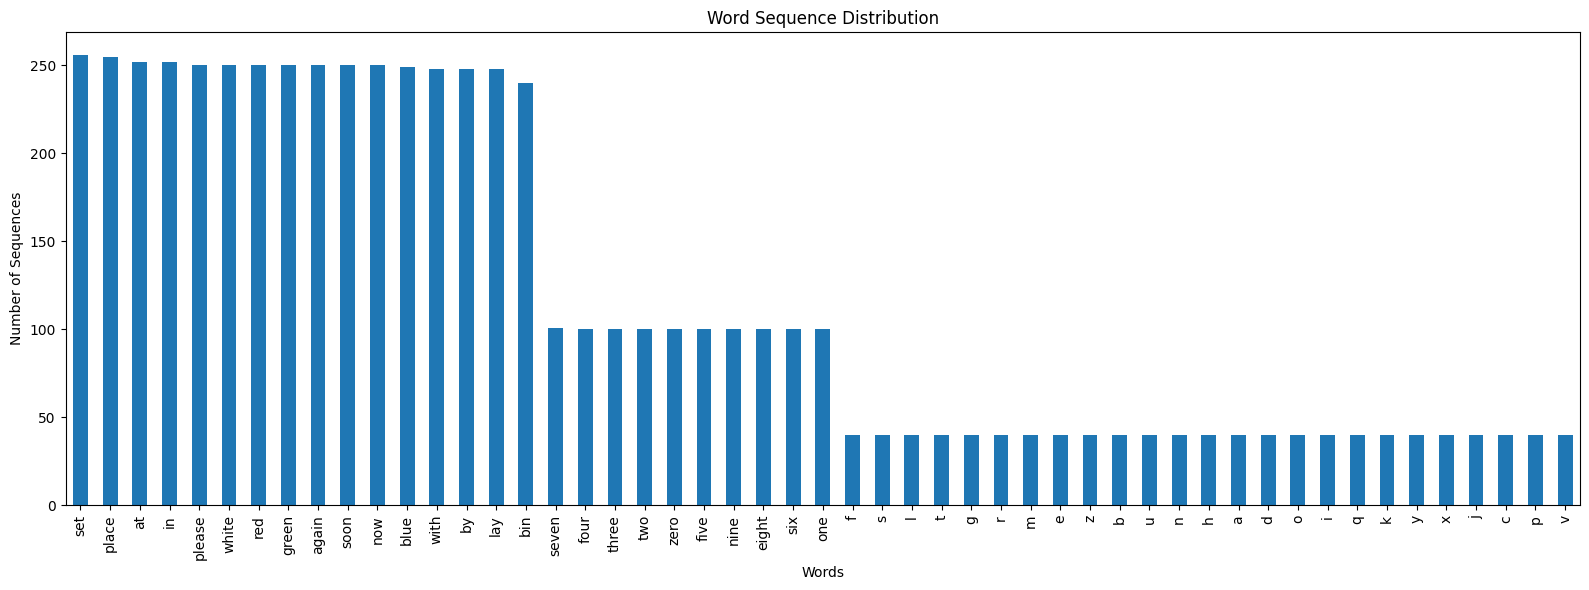

Minimum sequences per word: 40
Maximum sequences per word: 256
Average sequences per word: 117.63


In [34]:
import matplotlib.pyplot as plt

word_distribution = sequence_df["word"].value_counts()

plt.figure(figsize=(16, 6))
word_distribution.plot(kind="bar")

plt.title("Word Sequence Distribution")
plt.xlabel("Words")
plt.ylabel("Number of Sequences")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Minimum sequences per word:", word_distribution.min())
print("Maximum sequences per word:", word_distribution.max())
print("Average sequences per word:", round(word_distribution.mean(), 2))

In [35]:
train_sequences = sequence_df[
    sequence_df["video"].isin(train_videos)
].copy()

val_sequences = sequence_df[
    sequence_df["video"].isin(val_videos)
].copy()

test_sequences = sequence_df[
    sequence_df["video"].isin(test_videos)
].copy()

train_sequences.to_csv(
    os.path.join(BATCH_OUTPUT, "train_sequences.csv"),
    index=False
)

val_sequences.to_csv(
    os.path.join(BATCH_OUTPUT, "validation_sequences.csv"),
    index=False
)

test_sequences.to_csv(
    os.path.join(BATCH_OUTPUT, "test_sequences.csv"),
    index=False
)

print("Training sequences:", len(train_sequences))
print("Validation sequences:", len(val_sequences))
print("Testing sequences:", len(test_sequences))

print("\nTraining videos:", train_sequences["video"].nunique())
print("Validation videos:", val_sequences["video"].nunique())
print("Testing videos:", test_sequences["video"].nunique())

print("\nTraining word classes:", train_sequences["word"].nunique())

Training sequences: 4799
Validation sequences: 600
Testing sequences: 600

Training videos: 800
Validation videos: 100
Testing videos: 100

Training word classes: 51


In [36]:
print("Sequence length percentiles:")
print(sequence_df["sequence_length"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
))

for length in [8, 12, 16, 21]:
    short = (sequence_df["sequence_length"] < length).sum()
    long = (sequence_df["sequence_length"] > length).sum()

    print(
        f"\nLength {length}: "
        f"Padding: {short}, "
        f"Truncating: {long}"
    )

Sequence length percentiles:
0.50     6.0
0.75     8.0
0.90    10.0
0.95    11.0
0.99    13.0
Name: sequence_length, dtype: float64

Length 8: Padding: 4301, Truncating: 1073

Length 12: Padding: 5848, Truncating: 88

Length 16: Padding: 5977, Truncating: 11

Length 21: Padding: 5997, Truncating: 0


In [37]:
import json
import os

MAX_FRAMES = 16

word_classes = sorted(sequence_df["word"].unique())

word_to_index = {
    word: index
    for index, word in enumerate(word_classes)
}

index_to_word = {
    index: word
    for word, index in word_to_index.items()
}

with open(os.path.join(BATCH_OUTPUT, "word_labels.json"), "w") as f:
    json.dump(word_to_index, f, indent=4)

train_sequences["label"] = train_sequences["word"].map(word_to_index)
val_sequences["label"] = val_sequences["word"].map(word_to_index)
test_sequences["label"] = test_sequences["word"].map(word_to_index)

print("Maximum sequence length:", MAX_FRAMES)
print("Total word classes:", len(word_classes))
print("\nWord-to-index mapping:")
print(word_to_index)

print("\nTraining sequences:", len(train_sequences))
print("Validation sequences:", len(val_sequences))
print("Testing sequences:", len(test_sequences))

Maximum sequence length: 16
Total word classes: 51

Word-to-index mapping:
{'a': 0, 'again': 1, 'at': 2, 'b': 3, 'bin': 4, 'blue': 5, 'by': 6, 'c': 7, 'd': 8, 'e': 9, 'eight': 10, 'f': 11, 'five': 12, 'four': 13, 'g': 14, 'green': 15, 'h': 16, 'i': 17, 'in': 18, 'j': 19, 'k': 20, 'l': 21, 'lay': 22, 'm': 23, 'n': 24, 'nine': 25, 'now': 26, 'o': 27, 'one': 28, 'p': 29, 'place': 30, 'please': 31, 'q': 32, 'r': 33, 'red': 34, 's': 35, 'set': 36, 'seven': 37, 'six': 38, 'soon': 39, 't': 40, 'three': 41, 'two': 42, 'u': 43, 'v': 44, 'white': 45, 'with': 46, 'x': 47, 'y': 48, 'z': 49, 'zero': 50}

Training sequences: 4799
Validation sequences: 600
Testing sequences: 600


Video: bbaf2n
Word: bin
Sequence length: 6


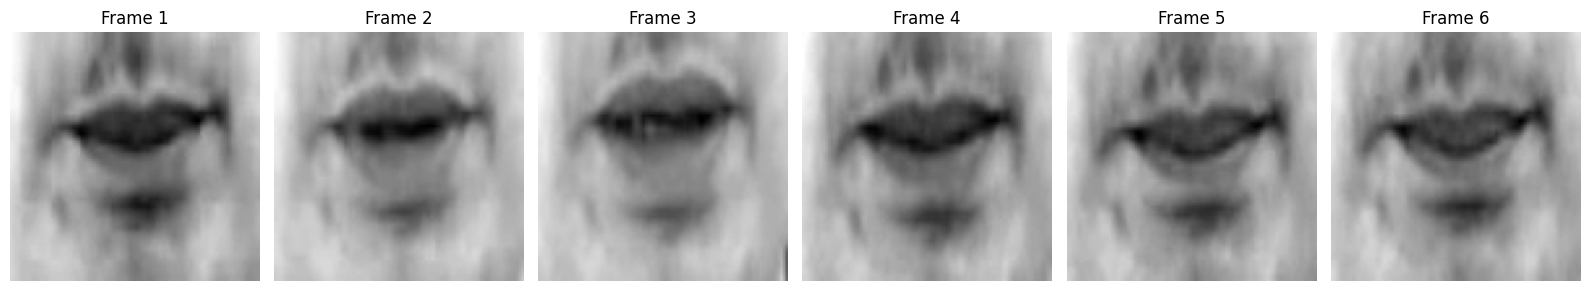

In [38]:
import cv2
import json
import matplotlib.pyplot as plt

sample = train_sequences.iloc[0]

image_paths = json.loads(sample["image_paths"])

print("Video:", sample["video"])
print("Word:", sample["word"])
print("Sequence length:", len(image_paths))

fig, axes = plt.subplots(1, min(8, len(image_paths)), figsize=(16, 3))

for i, path in enumerate(image_paths[:8]):
    image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    axes[i].imshow(image, cmap="gray")
    axes[i].set_title(f"Frame {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [39]:
import tensorflow as tf
import numpy as np
import json
import cv2
import os

IMG_SIZE = 96
MAX_FRAMES = 16
BATCH_SIZE = 16
NUM_CLASSES = 51

class LipReadingGenerator(tf.keras.utils.Sequence):

    def __init__(self, dataframe, batch_size=16, shuffle=True):
        self.df = dataframe.reset_index(drop=True)
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[
            index * self.batch_size:
            (index + 1) * self.batch_size
        ]

        batch = self.df.iloc[batch_indices]

        X = np.zeros(
            (len(batch), MAX_FRAMES, IMG_SIZE, IMG_SIZE, 1),
            dtype=np.float32
        )

        y = batch["label"].to_numpy(dtype=np.int32)

        for i, (_, row) in enumerate(batch.iterrows()):

            paths = json.loads(row["image_paths"])
            images = []

            for path in paths[:MAX_FRAMES]:
                image = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

                if image is None:
                    raise ValueError(f"Image not found: {path}")

                image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
                image = image.astype(np.float32) / 255.0
                images.append(image)

            if len(images) == 0:
                raise ValueError("Empty image sequence")

            while len(images) < MAX_FRAMES:
                images.append(images[-1].copy())

            X[i] = np.expand_dims(np.array(images), axis=-1)

        return X, y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


train_generator = LipReadingGenerator(train_sequences)
val_generator = LipReadingGenerator(val_sequences, shuffle=False)
test_generator = LipReadingGenerator(test_sequences, shuffle=False)

print("Training batches:", len(train_generator))
print("Validation batches:", len(val_generator))
print("Testing batches:", len(test_generator))

Training batches: 300
Validation batches: 38
Testing batches: 38


In [40]:
X_sample, y_sample = train_generator[0]

print("Input shape:", X_sample.shape)
print("Label shape:", y_sample.shape)
print("Image minimum:", X_sample.min())
print("Image maximum:", X_sample.max())
print("First 5 labels:", y_sample[:5])

Input shape: (16, 16, 96, 96, 1)
Label shape: (16,)
Image minimum: 0.11764706
Image maximum: 0.76862746
First 5 labels: [34 46 20  1 25]


In [41]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, TimeDistributed, Conv2D,
    MaxPooling2D, Flatten, LSTM,
    Dense, Dropout, BatchNormalization
)

model = Sequential([
    Input(shape=(16, 96, 96, 1)),

    TimeDistributed(Conv2D(32, (3, 3), activation="relu", padding="same")),
    TimeDistributed(BatchNormalization()),
    TimeDistributed(MaxPooling2D((2, 2))),

    TimeDistributed(Conv2D(64, (3, 3), activation="relu", padding="same")),
    TimeDistributed(BatchNormalization()),
    TimeDistributed(MaxPooling2D((2, 2))),

    TimeDistributed(Conv2D(128, (3, 3), activation="relu", padding="same")),
    TimeDistributed(MaxPooling2D((2, 2))),

    TimeDistributed(Flatten()),

    LSTM(128, return_sequences=False),
    Dropout(0.4),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ time_distributed                │ (None, 16, 96, 96, 32) │           320 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 16, 96, 96, 32) │           128 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 16, 48, 48, 32) │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_3              │ (None, 16, 48, 48, 64) │        18,496 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_4              │ (None, 16, 48, 48, 64) │           256 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_5              │ (None, 16, 24, 24, 64) │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_6              │ (None, 16, 24, 24,     │        73,856 │
│ (TimeDistributed)               │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_7              │ (None, 16, 12, 12,     │             0 │
│ (TimeDistributed)               │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_8              │ (None, 16, 18432)      │             0 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │     9,503,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 51)             │         3,315 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,607,859 (36.65 MB)

 Trainable params: 9,607,667 (36.65 MB)

 Non-trainable params: 192 (768.00 B)

In [42]:
import os
import tensorflow as tf

MODEL_DIR = os.path.join(BATCH_OUTPUT, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR, "best_lipreading_model.keras"
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.000001,
        verbose=1
    )
]

print("Training callbacks ready.")
print("Best model will be saved at:", BEST_MODEL_PATH)

Training callbacks ready.
Best model will be saved at: /content/drive/MyDrive/data (1)/outputs/full_dataset/models/best_lipreading_model.keras


In [43]:
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

print("GPU available:", len(gpus) > 0)
print("GPU devices:", gpus)

GPU available: False
GPU devices: []


In [47]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    steps_per_epoch=50,
    validation_steps=10,
    epochs=1,
    callbacks=callbacks,
    verbose=1
)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.0413 - loss: 3.9646
Epoch 1: val_accuracy improved from None to 0.17500, saving model to /content/drive/MyDrive/data (1)/outputs/full_dataset/models/best_lipreading_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/data (1)/outputs/full_dataset/models/best_lipreading_model.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 437s 9s/step - accuracy: 0.0350 - loss: 3.9776 - val_accuracy: 0.1750 - val_loss: 3.7679 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 1.


In [48]:
test_loss, test_accuracy = model.evaluate(
    test_generator,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

150/150 ━━━━━━━━━━━━━━━━━━━━ 108s 720ms/step - accuracy: 0.0417 - loss: 3.8518
Test Loss: 3.851775646209717
Test Accuracy: 4.17 %


In [49]:
print("Final training accuracy:",
      round(history.history["accuracy"][-1] * 100, 2), "%")

print("Final validation accuracy:",
      round(history.history["val_accuracy"][-1] * 100, 2), "%")

Final training accuracy: 3.5 %
Final validation accuracy: 17.5 %


In [50]:
history_more = model.fit(
    train_generator,
    validation_data=val_generator,
    steps_per_epoch=200,
    validation_steps=38,
    epochs=1,
    callbacks=callbacks,
    verbose=1
)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.0522 - loss: 3.8746
Epoch 1: val_accuracy did not improve from 0.17500
200/200 ━━━━━━━━━━━━━━━━━━━━ 1728s 9s/step - accuracy: 0.0362 - loss: 3.8775 - val_accuracy: 0.0461 - val_loss: 3.8379 - learning_rate: 1.0000e-04
Restoring model weights from the end of the best epoch: 1.


In [51]:
import os, json
import numpy as np
import pandas as pd
import tensorflow as tf

MODEL_PATH = os.path.join(BATCH_OUTPUT, "models", "best_lipreading_model.keras")

model = tf.keras.models.load_model(MODEL_PATH)

test_generator = LipReadingGenerator(
    test_sequences, batch_size=4, shuffle=False
)

predictions = []

for i in range(len(test_generator)):
    X, y = test_generator[i]
    probs = model.predict(X, verbose=0)
    predicted = np.argmax(probs, axis=1)

    batch = test_sequences.iloc[i*4:i*4+len(y)]

    for j, (_, row) in enumerate(batch.iterrows()):
        predictions.append({
            "video": row["video"],
            "actual_word": index_to_word[int(y[j])],
            "predicted_word": index_to_word[int(predicted[j])]
        })

prediction_df = pd.DataFrame(predictions)

prediction_df.to_csv(
    os.path.join(BATCH_OUTPUT, "lip_predictions.csv"),
    index=False
)

print("Predictions generated:", len(prediction_df))
display(prediction_df.head(10))


Predictions generated: 600


,video,actual_word,predicted_word
0,bbie8n,bin,bin
1,bbie8n,blue,bin
2,bbie8n,in,bin
3,bbie8n,e,bin
4,bbie8n,eight,bin
5,bbie8n,now,bin
6,bbir7s,bin,bin
7,bbir7s,blue,bin
8,bbir7s,in,bin
9,bbir7s,r,bin


In [52]:
transcript_df = (
    prediction_df.groupby("video")
    .agg(
        actual_transcript=("actual_word", " ".join),
        predicted_transcript=("predicted_word", " ".join)
    )
    .reset_index()
)

transcript_df.to_csv(
    os.path.join(BATCH_OUTPUT, "lip_transcripts.csv"),
    index=False
)

print("Transcripts generated:", len(transcript_df))
display(transcript_df.head())


Transcripts generated: 100


,video,actual_transcript,predicted_transcript
0,bbie8n,bin blue in e eight now,bin bin bin bin bin bin
1,bbir7s,bin blue in r seven soon,bin bin bin bin bin bin
2,bbiz3a,bin blue in z three again,bin bin bin bin bin bin
3,bbws8n,bin blue with s eight now,bin bin bin bin bin bin
4,bbws9s,bin blue with s nine soon,bin bin bin bin bin bin


In [53]:
import os, subprocess

AUDIO_PATH = os.path.join(OUTPUT_PATH, "asr_audio")
os.makedirs(AUDIO_PATH, exist_ok=True)

for video in transcript_df["video"]:
    source = os.path.join(VIDEO_PATH, video + ".mpg")
    target = os.path.join(AUDIO_PATH, video + ".wav")

    if not os.path.exists(target):
        subprocess.run([
            "ffmpeg", "-y", "-i", source,
            "-vn", "-ac", "1", "-ar", "16000", target
        ], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

print("Audio extraction completed.")
print("Audio files:", len(os.listdir(AUDIO_PATH)))


Audio extraction completed.
Audio files: 100


In [55]:

!pip install -q --upgrade a

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/data (1)"
BATCH_OUTPUT = os.path.join(BASE_PATH, "outputs", "full_dataset")
AUDIO_PATH = os.path.join(BASE_PATH, "outputs", "asr_audio")

print("Drive exists:", os.path.exists(BASE_PATH))
print("Transcript file exists:", os.path.exists(
    os.path.join(BATCH_OUTPUT, "lip_transcripts.csv")
))
print("Audio folder exists:", os.path.exists(AUDIO_PATH))

if os.path.exists(os.path.join(BATCH_OUTPUT, "lip_transcripts.csv")):
    transcript_df = pd.read_csv(
        os.path.join(BATCH_OUTPUT, "lip_transcripts.csv")
    )
    print("Transcript rows:", len(transcript_df))

if os.path.exists(AUDIO_PATH):
    print("Audio files:", len(os.listdir(AUDIO_PATH)))

Drive exists: True
Transcript file exists: True
Audio folder exists: True
Transcript rows: 100
Audio files: 100


In [6]:
!pip install -q openai-whisper

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [7]:
import whisper as openai_whisper
import os
import pandas as pd

model = openai_whisper.load_model("tiny.en")

audio_results = []

for video in transcript_df["video"]:
    path = os.path.join(AUDIO_PATH, video + ".wav")

    result = model.transcribe(path, fp16=False)

    audio_results.append({
        "video": video,
        "audio_transcript": result["text"].strip()
    })

audio_df = pd.DataFrame(audio_results)

audio_df.to_csv(
    os.path.join(BATCH_OUTPUT, "audio_transcripts.csv"),
    index=False
)

print("Audio transcripts generated:", len(audio_df))
display(audio_df.head())

100%|█████████████████████████████████████| 72.1M/72.1M [00:00<00:00, 89.7MiB/s]


Audio transcripts generated: 100


,video,audio_transcript
0,bbie8n,Bimpler in E8 now.
1,bbir7s,Bimply in R7 soon.
2,bbiz3a,Bimblur in Z3 again.
3,bbws8n,"Bim blue, if I say it now."
4,bbws9s,Then blue with S9 soon.


In [8]:
combined_df = pd.merge(
    transcript_df,
    audio_df,
    on="video",
    how="inner"
)

combined_df.to_csv(
    os.path.join(BATCH_OUTPUT, "combined_transcripts.csv"),
    index=False
)

print("Combined videos:", len(combined_df))
display(combined_df.head())

Combined videos: 100


,video,actual_transcript,predicted_transcript,audio_transcript
0,bbie8n,bin blue in e eight now,bin bin bin bin bin bin,Bimpler in E8 now.
1,bbir7s,bin blue in r seven soon,bin bin bin bin bin bin,Bimply in R7 soon.
2,bbiz3a,bin blue in z three again,bin bin bin bin bin bin,Bimblur in Z3 again.
3,bbws8n,bin blue with s eight now,bin bin bin bin bin bin,"Bim blue, if I say it now."
4,bbws9s,bin blue with s nine soon,bin bin bin bin bin bin,Then blue with S9 soon.


In [9]:
!pip install -q jiwer

from jiwer import wer
import os

references = []

for video in combined_df["video"]:
    path = os.path.join(ALIGN_PATH, video + ".align")
    words = []

    with open(path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) == 3 and parts[2] not in ["sil", "sp", "unknown"]:
                words.append(parts[2])

    references.append(" ".join(words))

combined_df["reference_transcript"] = references

combined_df["audio_wer"] = [
    wer(ref.lower(), hyp.lower())
    for ref, hyp in zip(
        combined_df["reference_transcript"],
        combined_df["audio_transcript"]
    )
]

print("Average Whisper WER:", round(combined_df["audio_wer"].mean(), 4))
print("Average Whisper accuracy estimate:",
      round((1 - combined_df["audio_wer"].mean()) * 100, 2), "%")

display(combined_df[[
    "video", "reference_transcript", "audio_transcript", "audio_wer"
]].head())


Average Whisper WER: 0.6933
Average Whisper accuracy estimate: 30.67 %


,video,reference_transcript,audio_transcript,audio_wer
0,bbie8n,bin blue in e eight now,Bimpler in E8 now.,0.833333
1,bbir7s,bin blue in r seven soon,Bimply in R7 soon.,0.833333
2,bbiz3a,bin blue in z three again,Bimblur in Z3 again.,0.833333
3,bbws8n,bin blue with s eight now,"Bim blue, if I say it now.",1.166667
4,bbws9s,bin blue with s nine soon,Then blue with S9 soon.,0.666667


In [10]:
!pip install -q transformers sentencepiece

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

name = "google/flan-t5-small"
tokenizer = AutoTokenizer.from_pretrained(name)
summarizer = AutoModelForSeq2SeqLM.from_pretrained(name)

def summarize(text):
    prompt = "Summarize this transcript: " + str(text)
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True)

    with torch.no_grad():
        output = summarizer.generate(**inputs, max_new_tokens=60)

    return tokenizer.decode(output[0], skip_special_tokens=True)

combined_df["summary"] = combined_df["audio_transcript"].apply(summarize)

combined_df.to_csv(
    os.path.join(BATCH_OUTPUT, "final_project_results.csv"),
    index=False
)

print("Summarization completed!")
display(combined_df[["video", "audio_transcript", "summary"]].head())


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Summarization completed!


,video,audio_transcript,summary
0,bbie8n,Bimpler in E8 now.,The bimpler is now in the E8.
1,bbir7s,Bimply in R7 soon.,The sands of the sands of the sands of the san...
2,bbiz3a,Bimblur in Z3 again.,Bimblur in Z3 again.
3,bbws8n,"Bim blue, if I say it now.","I'm a little blue, but I'm a little blue."
4,bbws9s,Then blue with S9 soon.,Then a sanded sanded sanded sanded sanded sand...


In [12]:
import os
import pandas as pd

BASE_PATH = "/content/drive/MyDrive/data (1)"
BATCH_OUTPUT = os.path.join(BASE_PATH, "outputs", "full_dataset")

prediction_df = pd.read_csv(
    os.path.join(BATCH_OUTPUT, "lip_predictions.csv")
)

print("Predictions loaded:", len(prediction_df))

Predictions loaded: 600


Lip-reading accuracy: 4.17 %


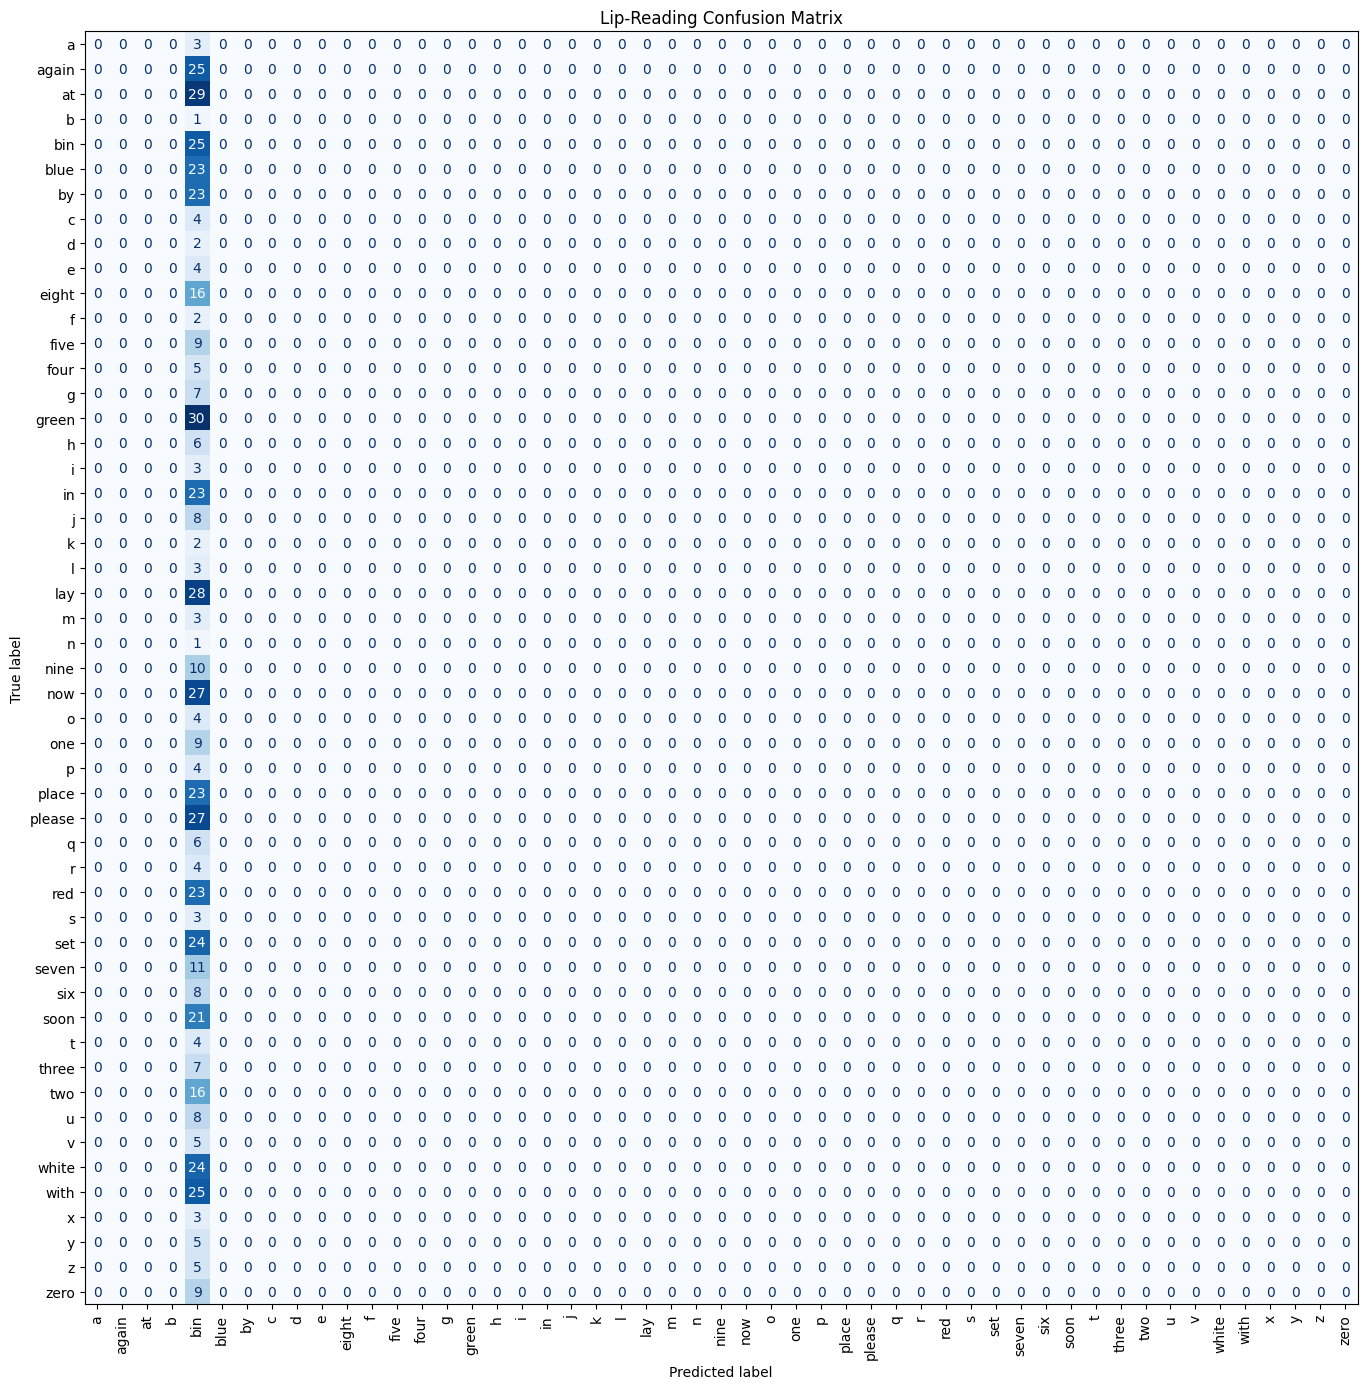

Evaluation report and confusion matrix saved.


In [13]:
!pip install -q scikit-learn

import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay, confusion_matrix
)

y_true = prediction_df["actual_word"]
y_pred = prediction_df["predicted_word"]

print("Lip-reading accuracy:", round(accuracy_score(y_true, y_pred)*100, 2), "%")

report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
pd.DataFrame(report).transpose().to_csv(
    os.path.join(BATCH_OUTPUT, "lipreading_evaluation.csv")
)

labels = sorted(y_true.unique())
cm = confusion_matrix(y_true, y_pred, labels=labels)

plt.figure(figsize=(16, 14))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(
    ax=plt.gca(), xticks_rotation=90, cmap="Blues", colorbar=False
)
plt.title("Lip-Reading Confusion Matrix")
plt.tight_layout()

plt.savefig(os.path.join(BATCH_OUTPUT, "confusion_matrix.png"))
plt.show()

print("Evaluation report and confusion matrix saved.")


Lip-reading WER: 0.9583
Whisper WER: 0.6933


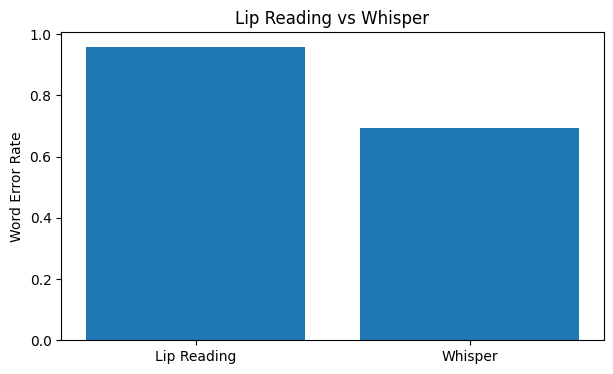

In [14]:
import matplotlib.pyplot as plt
from jiwer import wer

lip_wer = combined_df.apply(
    lambda r: wer(r["reference_transcript"].lower(),
                  r["predicted_transcript"].lower()), axis=1
).mean()

audio_wer = combined_df["audio_wer"].mean()

print("Lip-reading WER:", round(lip_wer, 4))
print("Whisper WER:", round(audio_wer, 4))

plt.figure(figsize=(7, 4))
plt.bar(["Lip Reading", "Whisper"], [lip_wer, audio_wer])
plt.ylabel("Word Error Rate")
plt.title("Lip Reading vs Whisper")
plt.savefig(os.path.join(BATCH_OUTPUT, "wer_comparison.png"))
plt.show()

In [15]:
results = pd.DataFrame({
    "Metric": [
        "Lip Reading Test Accuracy",
        "Lip Reading WER",
        "Whisper WER"
    ],
    "Result": [4.17, 95.83, 69.33],
    "Unit": ["%", "%", "%"]
})

results.to_csv(
    os.path.join(BATCH_OUTPUT, "final_evaluation.csv"),
    index=False
)

display(results)
print("Final evaluation saved successfully!")


,Metric,Result,Unit
0,Lip Reading Test Accuracy,4.17,%
1,Lip Reading WER,95.83,%
2,Whisper WER,69.33,%


Final evaluation saved successfully!
